# Clasificación de Razas de Perros con Red Neuronal Convolucional

## 1. Definición del problema

El objetivo de esta práctica es construir una red neuronal convolucional (CNN) capaz de clasificar imágenes de perros en **tres razas**:
* **bulldog**
* **golden_retriever**
* **pastor_aleman**

### ¿Por qué no se puede resolver con programación tradicional?

La clasificación de razas de perros **no puede resolverse con programación tradicional** (reglas if/else, umbrales de color, detección de bordes) por los siguientes motivos:

1. **Variabilidad visual extrema**: Un bulldog puede ser blanco, atigrado o marrón, fotografiado de frente, de lado o en movimiento. Las reglas basadas en color o contorno no capturan estas variaciones.
2. **Características sutiles entre razas**: La diferencia entre razas reside en proporciones del hocico, forma de las orejas o textura del pelaje. Estos rasgos no pueden describirse con reglas simples.
3. **Condiciones variables de captura**: Distintas iluminaciones, fondos, ángulos o resoluciones cambian completamente el aspecto de la misma imagen.
4. **Oclusión y poses**: Un perro puede aparecer parcialmente tapado, tumbado o saltando. Los enfoques clásicos no manejan estas situaciones.
5. **Escalabilidad**: Añadir nuevas razas a un sistema basado en reglas requeriría reescribir toda la lógica. Con CNN basta con reentrenar.

**Conclusión**: Este problema requiere aprendizaje de representaciones visuales complejas desde los datos, siendo las CNN el enfoque más adecuado.

---
### Flujo de trabajo de este notebook
* Importar librerías
* Definir parámetros
* Cargar datasets de entrenamiento y test
* Normalización y aumentación de datos
* Construcción de la CNN
* Compilación del modelo
* Entrenamiento con Early Stopping
* Visualización del entrenamiento
* Evaluación: Matriz de confusión, Accuracy, Precision, Recall, F1-score
* Visualización Grad-CAM
* Exportación del modelo

## 2. Importación de librerías

In [18]:
from keras.utils import image_dataset_from_directory        # Carga automática de imágenes desde carpetas
from keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation  # Aumentación de datos
from keras.layers import Rescaling                          # Normalización de píxeles de 0-255 a 0-1
from keras.models import Sequential                         # Permite construir el modelo capa por capa
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, Flatten, Dropout
from keras.callbacks import EarlyStopping                   # Detiene el entrenamiento si no mejora
import keras
import numpy as np
import os
import PIL.Image as Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

## 3. Parámetros de la aplicación

Todos los hiperparámetros están centralizados aquí para poder ajustarlos fácilmente sin modificar el resto del código.

In [19]:
tam_imagen    = 128        # Tamaño al que se redimensionan las imágenes (128x128 px)
batch_size    = 32         # Número de imágenes procesadas por batch en cada paso
epochs        = 30         # Número máximo de épocas de entrenamiento
learning_rate = 0.001      # Tasa de aprendizaje del optimizador Adam
dropout_rate  = 0.4        # Fracción de neuronas desactivadas en Dropout para evitar sobreajuste
patience      = 7          # Épocas sin mejora antes de detener el entrenamiento (Early Stopping)

carpeta_train  = '.\\imagenes_perros\\train'
carpeta_test   = '.\\imagenes_perros\\test'
carpeta_prueba = '.\\imagenes_perros\\prueba'

# Orden alfabético = orden en que Keras asigna índices a las carpetas
clases = ['bulldog', 'golden_retriever', 'pastor_aleman']

print('Parámetros cargados correctamente')
print(f'  Clases         : {clases}')
print(f'  Tamaño imagen  : {tam_imagen}x{tam_imagen} px')
print(f'  Batch size     : {batch_size}')
print(f'  Épocas máx.    : {epochs}')
print(f'  Learning rate  : {learning_rate}')
print(f'  Dropout        : {dropout_rate}')
print(f'  Early Stopping : patience={patience}')

Parámetros cargados correctamente
  Clases         : ['bulldog', 'golden_retriever', 'pastor_aleman']
  Tamaño imagen  : 128x128 px
  Batch size     : 32
  Épocas máx.    : 30
  Learning rate  : 0.001
  Dropout        : 0.4
  Early Stopping : patience=7


## 4. Carga de datos

Se cargan los datasets de entrenamiento y test desde las carpetas indicadas.

Estructura esperada de carpetas:
```
imagenes_perros/
  train/
    bulldog/           (mínimo 100 imágenes)
    golden_retriever/  (mínimo 100 imágenes)
    pastor_aleman/     (mínimo 100 imágenes)
  test/
    bulldog/           (mínimo 30 imágenes)
    golden_retriever/  (mínimo 30 imágenes)
    pastor_aleman/     (mínimo 30 imágenes)
  prueba/              (imágenes sueltas para demostración)
```

**labels='inferred'** → las etiquetas se deducen automáticamente a partir del nombre de las carpetas.  
**label_mode='categorical'** → porque tenemos más de dos clases, las etiquetas se codifican en formato one-hot.

In [20]:
train_dataset = image_dataset_from_directory(
    carpeta_train,
    image_size=(tam_imagen, tam_imagen),
    batch_size=batch_size,
    labels='inferred',
    label_mode='categorical',
    class_names=clases
)

test_dataset = image_dataset_from_directory(
    carpeta_test,
    image_size=(tam_imagen, tam_imagen),
    batch_size=batch_size,
    labels='inferred',
    label_mode='categorical',
    class_names=clases
)

Found 300 files belonging to 3 classes.
Found 158 files belonging to 3 classes.


### Visualización de muestras del dataset

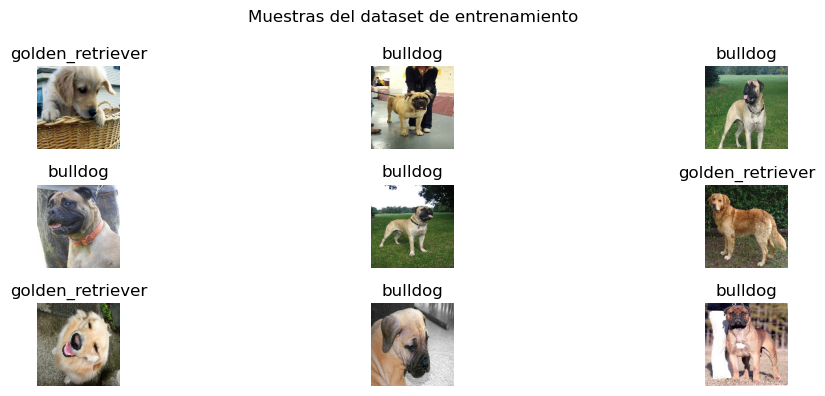

In [21]:
plt.figure(figsize=(12, 4))
for imagenes, etiquetas in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imagenes[i].numpy().astype('uint8'))
        idx = np.argmax(etiquetas[i])
        plt.title(clases[idx])
        plt.axis('off')
plt.suptitle('Muestras del dataset de entrenamiento')
plt.tight_layout()
plt.show()

## 5. Normalización

Se usa `Rescaling(1./255)` para convertir los píxeles de:
- 0-255

a:
- 0-1

Ventaja:
- facilita el entrenamiento
- mejora la estabilidad numérica del modelo
- el modelo trabaja mejor con valores numéricos pequeños

In [22]:
normalizar = Rescaling(1./255)

## 6. Aumentación de datos

La aumentación de datos crea versiones modificadas de las imágenes originales:
- volteo horizontal
- rotación
- zoom
- desplazamiento

Objetivo:
- aumentar artificialmente la variedad del dataset
- evitar sobreajuste
- mejorar la generalización del modelo

Sirve para que el modelo no memorice solo las imágenes exactas, sino que aprenda el concepto de raza aunque cambie la posición, la luz o el ángulo.  
Se aplica **solo en entrenamiento** (no en test).

In [23]:
data_augmentation = Sequential([
    RandomFlip('horizontal'),       # Volteo horizontal
    RandomRotation(0.2),            # Rotaciones de hasta el 20% de 360º
    RandomZoom(0.1),                # Zoom de hasta el 10% (hacia dentro/fuera)
    RandomTranslation(0.1, 0.1)     # Desplazamiento vertical y horizontal
])

## 7. Aplicación del preprocesado al dataset

In [24]:
# normaliza + aplica aumentación (rotar, zoom, etc.) solo al train
def procesar_train(x, y):
    x = normalizar(x)
    x = data_augmentation(x)
    return x, y

# solo normaliza el test, sin aumentación
def procesar_test(x, y):
    x = normalizar(x)
    return x, y

# map() aplica la función a todos los elementos del dataset
train_dataset = train_dataset.map(procesar_train)
test_dataset  = test_dataset.map(procesar_test)

## 8. Construcción del modelo CNN

La red tiene estas partes:

1. **Input (128,128,3)**  
   Recibe imágenes RGB de 128x128 px.

2. **Conv2D(32, 3x3, relu)**  
   Detecta patrones simples como bordes y texturas de pelo.

3. **MaxPooling2D(2x2)**  
   Reduce el tamaño del mapa de características conservando la información más relevante.

4. **Conv2D(64, 3x3, relu)**  
   Detecta patrones más complejos como orejas, hocico o ojos.

5. **MaxPooling2D(2x2)**  
   Nueva reducción de tamaño.

6. **Conv2D(128, 3x3, relu)**  
   Aprende características de alto nivel que definen cada raza.

7. **MaxPooling2D(2x2)**  
   Tercera reducción de tamaño.

8. **Flatten()**  
   Convierte la información 2D en un vector 1D para pasar a las capas densas.

9. **Dense(256, relu)**  
   Aprende combinaciones de las características extraídas.

10. **Dropout(0.4)**  
    Desactiva el 40% de las neuronas aleatoriamente durante el entrenamiento para evitar sobreajuste.

11. **Dense(3, softmax)**  
    Devuelve la probabilidad para cada una de las 3 razas. La suma de las 3 probabilidades siempre es 1.

In [25]:
modelo = Sequential()

# Imagen de entrada: 128x128 px con 3 canales de color (RGB)
modelo.add(Input((tam_imagen, tam_imagen, 3)))

modelo.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2)))

modelo.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2)))

modelo.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2)))

modelo.add(Flatten())
modelo.add(Dense(256, activation='relu'))
modelo.add(Dropout(dropout_rate))
modelo.add(Dense(3, activation='softmax'))   # 3 clases → softmax

modelo.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,516,803 (24.86 MB)

 Trainable params: 6,516,803 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Compilación del modelo

- `optimizer='adam'`: método de optimización de pesos, con la tasa de aprendizaje definida en los parámetros
- `loss='categorical_crossentropy'`: función de error para clasificación con más de dos clases y etiquetas one-hot
- `metrics=['accuracy']`: mide el porcentaje de aciertos durante el entrenamiento

In [26]:
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## 10. Entrenamiento del modelo con Early Stopping

El entrenamiento se realiza con `fit()`.

- `train_dataset`: conjunto usado para aprender
- `validation_data=test_dataset`: conjunto usado para comprobar el rendimiento en cada época
- `epochs=30`: número máximo de veces que el modelo ve todo el dataset

**Early Stopping**: detiene el entrenamiento automáticamente cuando `val_loss` no mejora durante `patience` épocas consecutivas. `restore_best_weights=True` recupera los pesos del mejor momento del entrenamiento.

Durante el entrenamiento se observan:
- `loss` y `accuracy`: rendimiento en entrenamiento
- `val_loss` y `val_accuracy`: rendimiento en validación

Si el modelo aprende bien: baja la pérdida y sube la precisión.

In [27]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=patience,
    restore_best_weights=True,
    verbose=1
)

historial = modelo.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=epochs,
    callbacks=[early_stopping]
)

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 302ms/step - accuracy: 0.3233 - loss: 1.2143 - val_accuracy: 0.4367 - val_loss: 1.0816
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 270ms/step - accuracy: 0.4400 - loss: 1.0786 - val_accuracy: 0.3671 - val_loss: 1.0854
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 266ms/step - accuracy: 0.3433 - loss: 1.0941 - val_accuracy: 0.4241 - val_loss: 1.0792
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 263ms/step - accuracy: 0.3967 - loss: 1.0825 - val_accuracy: 0.4051 - val_loss: 1.0383
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 268ms/step - accuracy: 0.4133 - loss: 1.0494 - val_accuracy: 0.4873 - val_loss: 0.9888
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 263ms/step - accuracy: 0.4433 - loss: 1.0303 - val_accuracy: 0.4937 - val_loss: 0.9885
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 272ms/step - accuracy: 0.5067 - loss: 1.0018 - val_accuracy: 0.4937 - val_loss: 0.9756
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 269ms/step - accuracy: 0.4800 - loss: 0.9689 - val_accuracy: 0.

## 11. Visualización del entrenamiento

Se representan las curvas de accuracy y loss por época para comprobar si el modelo ha aprendido correctamente y si existe sobreajuste.

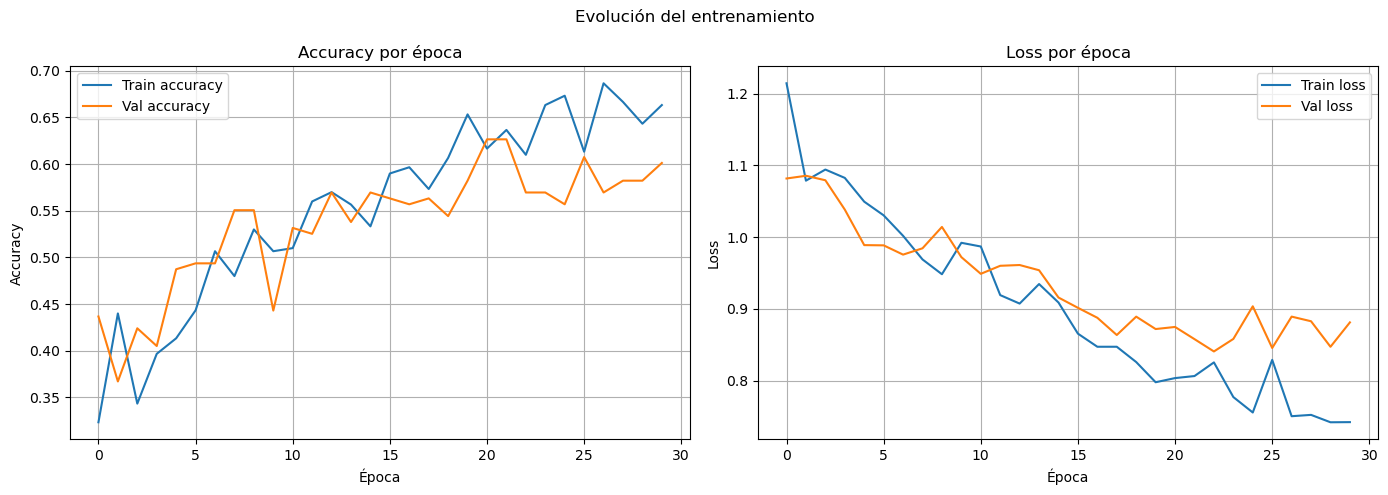

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(historial.history['accuracy'],     label='Train accuracy')
ax1.plot(historial.history['val_accuracy'], label='Val accuracy')
ax1.set_title('Accuracy por época')
ax1.set_xlabel('Época')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

ax2.plot(historial.history['loss'],     label='Train loss')
ax2.plot(historial.history['val_loss'], label='Val loss')
ax2.set_title('Loss por época')
ax2.set_xlabel('Época')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.suptitle('Evolución del entrenamiento')
plt.tight_layout()
plt.show()

## 12. Evaluación del modelo

### Matriz de confusión y métricas

Se obtienen las predicciones sobre el conjunto de test para calcular:
- **Accuracy**: proporción total de predicciones correctas
- **Precision**: de los que predice como clase X, ¿cuántos son realmente X?
- **Recall**: de los que son realmente clase X, ¿cuántos detecta el modelo?
- **F1-score**: media armónica de precision y recall, útil si las clases están desbalanceadas

In [29]:
# Recorrer el dataset de test para obtener etiquetas reales y predicciones
y_real = []
y_pred = []

for imagenes, etiquetas in test_dataset:
    predicciones = modelo.predict(imagenes, verbose=0)
    y_pred.extend(np.argmax(predicciones, axis=1))
    y_real.extend(np.argmax(etiquetas.numpy(), axis=1))

y_real = np.array(y_real)
y_pred = np.array(y_pred)

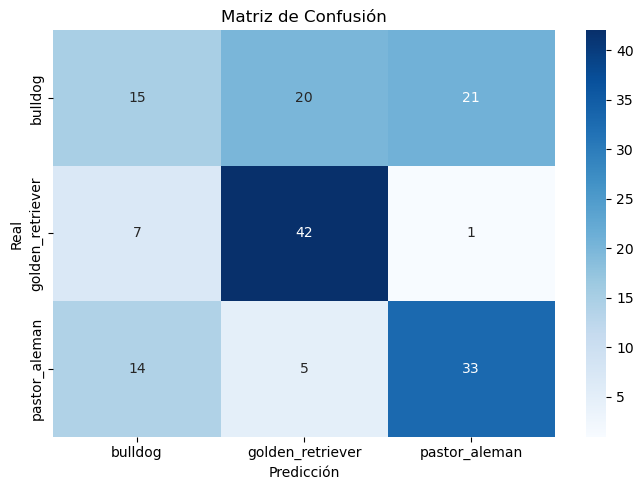

In [30]:
# Matriz de confusión
mc = confusion_matrix(y_real, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(mc, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases, yticklabels=clases)
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión')
plt.tight_layout()
plt.show()

In [31]:
# Métricas globales y por clase
print('=' * 45)
print('         MÉTRICAS DE EVALUACIÓN')
print('=' * 45)
print(f'Accuracy : {accuracy_score(y_real, y_pred):.4f}')
print(f'Precision: {precision_score(y_real, y_pred, average="macro"):.4f}')
print(f'Recall   : {recall_score(y_real, y_pred, average="macro"):.4f}')
print(f'F1-score : {f1_score(y_real, y_pred, average="macro"):.4f}')
print()
print('Informe detallado por clase:')
print(classification_report(y_real, y_pred, target_names=clases))

         MÉTRICAS DE EVALUACIÓN
Accuracy : 0.5696
Precision: 0.5478
Recall   : 0.5808
F1-score : 0.5536

Informe detallado por clase:
                  precision    recall  f1-score   support

         bulldog       0.42      0.27      0.33        56
golden_retriever       0.63      0.84      0.72        50
   pastor_aleman       0.60      0.63      0.62        52

        accuracy                           0.57       158
       macro avg       0.55      0.58      0.55       158
    weighted avg       0.54      0.57      0.55       158



## 13. Visualización Grad-CAM

**Grad-CAM** (Gradient-weighted Class Activation Mapping) es una técnica de interpretabilidad que permite visualizar qué zonas de la imagen han activado más la decisión del modelo. Genera un mapa de calor (heatmap) superpuesto sobre la imagen original.

Esto nos permite comprobar si el modelo está mirando correctamente al perro (hocico, orejas, pelaje) o si se fija en partes irrelevantes del fondo.

In [32]:
def obtener_gradcam(modelo, img_array):
    # Buscar la última capa Conv2D
    ultima_conv = None
    for capa in reversed(modelo.layers):
        if isinstance(capa, tf.keras.layers.Conv2D):
            ultima_conv = capa
            break

    # Separar el modelo en dos partes: hasta la conv y desde la conv hasta la salida
    idx_conv = modelo.layers.index(ultima_conv)
    capas_hasta_conv  = modelo.layers[:idx_conv + 1]
    capas_desde_conv  = modelo.layers[idx_conv + 1:]

    with tf.GradientTape() as tape:
        # Pasar la imagen por las capas hasta la última conv
        x = img_array
        for capa in capas_hasta_conv:
            x = capa(x)
        conv_output = x
        tape.watch(conv_output)

        # Continuar desde la conv hasta la salida
        y = conv_output
        for capa in capas_desde_conv:
            y = capa(y)

        clase_predicha = tf.argmax(y[0])
        loss = y[:, clase_predicha]

    grads = tape.gradient(loss, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    heatmap = conv_output[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)

    print(f'Capa usada: {ultima_conv.name} | Clase predicha: {clases[int(clase_predicha)]}')
    return heatmap.numpy(), int(clase_predicha)


def mostrar_gradcam(ruta_imagen, modelo, clases):
    img = Image.open(ruta_imagen).convert('RGB').resize((tam_imagen, tam_imagen))
    img_array = np.array(img) / 255.0
    img_input = img_array[np.newaxis, ...].astype('float32')

    heatmap, idx = obtener_gradcam(modelo, img_input)

    heatmap_color = cm.jet(np.uint8(255 * heatmap))[:, :, :3]
    heatmap_resized = np.array(
        Image.fromarray(np.uint8(heatmap_color * 255)).resize((tam_imagen, tam_imagen))
    ) / 255.0
    superposed = np.clip(0.6 * img_array + 0.4 * heatmap_resized, 0, 1)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(img_array);         axes[0].set_title('Imagen original');    axes[0].axis('off')
    axes[1].imshow(heatmap, cmap='jet'); axes[1].set_title('Heatmap Grad-CAM'); axes[1].axis('off')
    axes[2].imshow(superposed);        axes[2].set_title(f'Predicción: {clases[idx]}'); axes[2].axis('off')

    plt.suptitle('Visualización Grad-CAM')
    plt.tight_layout()
    plt.show()

--- Grad-CAM: Bulldog ---
Capa usada: conv2d_5 | Clase predicha: bulldog


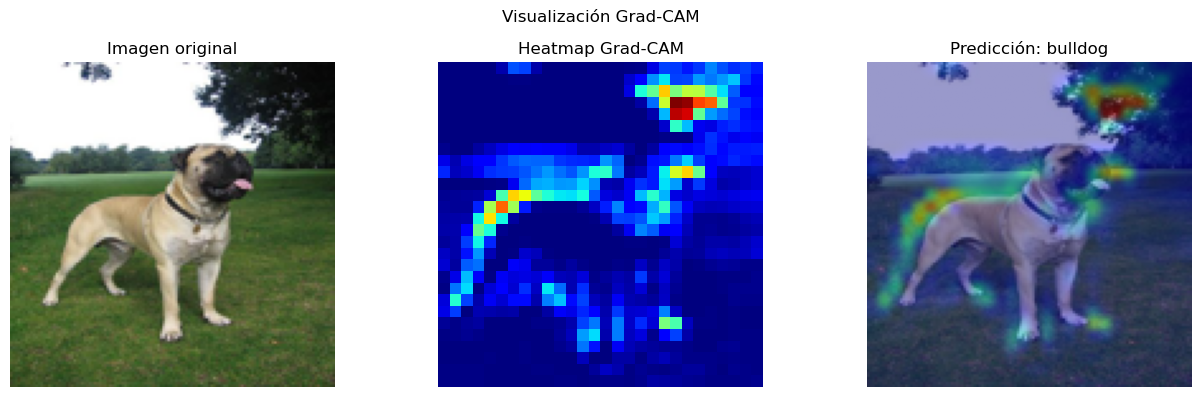

--- Grad-CAM: Golden Retriever ---
Capa usada: conv2d_5 | Clase predicha: golden_retriever


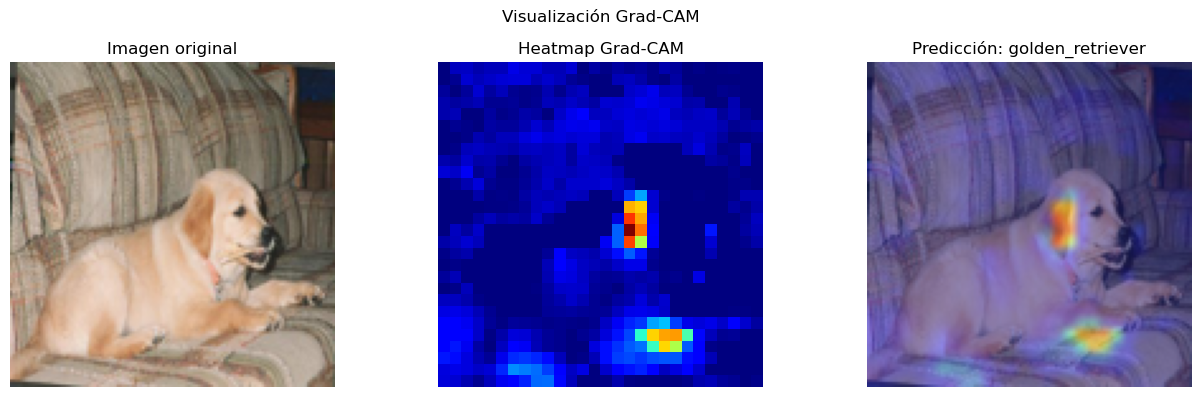

--- Grad-CAM: Pastor Alemán ---
Capa usada: conv2d_5 | Clase predicha: pastor_aleman


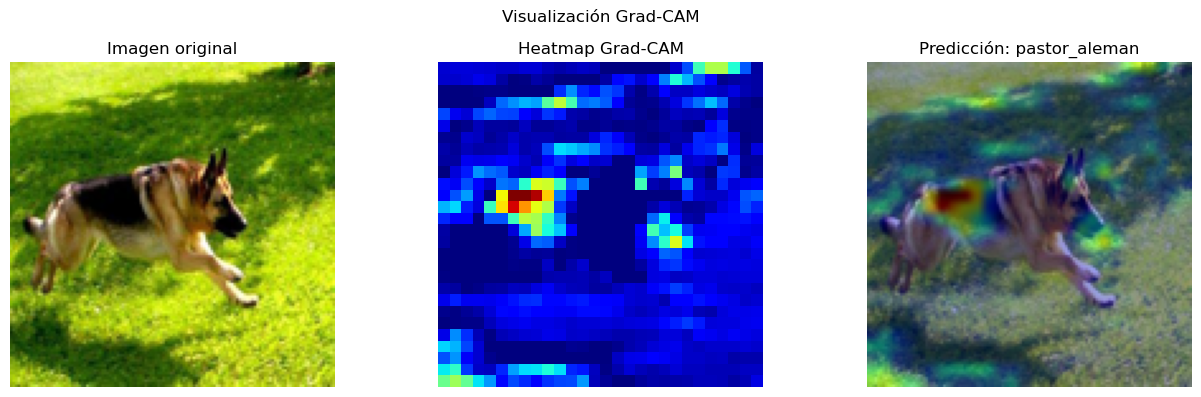

In [33]:
imagenes_gradcam = [
    ('.\\imagenes_perros\\prueba\\bulldog_prueba.jpg',          'Bulldog'),
    ('.\\imagenes_perros\\prueba\\golden_retriever_prueba.jpg', 'Golden Retriever'),
    ('.\\imagenes_perros\\prueba\\pastor_aleman_prueba.jpg',    'Pastor Alemán')
]

for ruta, nombre in imagenes_gradcam:
    print(f'--- Grad-CAM: {nombre} ---')
    mostrar_gradcam(ruta, modelo, clases)

## 14. Guardar el modelo

In [34]:
modelo.save('modelo_perros.keras')
print('Modelo guardado correctamente como modelo_perros.keras')

Modelo guardado correctamente como modelo_perros.keras
